# Counting overlapping populations with PCAT

## Assignment

Use PCAT to infer how many Gaussian populations produced a one-dimensional event catalog on top of a uniform background. The events below are synthetic, and the generating model is stated so you can compare the posterior with known truth without confusing a toy example for an observation.

The data are generated as a Poisson point process on the dimensionless interval $0 \leq x \leq 10$. A uniform background contributes events throughout the interval. Two Gaussian populations contribute events near separate centers. Each population has an expected event count, center, and width. The fitted catalog may contain zero through four populations. PCAT samples the background rate and the variable-length population catalog with birth, death, and within-model proposals.

## Learning goals

- Write an unbinned point-process likelihood and include its integrated-rate term.
- Run PCAT's transdimensional sampler through its public `sample_catalog` interface.
- Read the returned catalogs and summarize uncertainty in population count and location.
- Explain how the count prior, finite parameter bounds, and model assumptions affect the result.

## Work to submit

1. Run the notebook and inspect the displayed event sample and posterior summaries.
2. Report the posterior probability for each allowed population count and compare it with the known generating count.
3. Describe what the center distribution says about the two injected populations. Note where a single broad component or extra components could explain the data.
4. Repeat the run with a different `count_prior_mean` and explain which posterior summaries change.
5. State the limitations of this model. In particular, discuss the uniform background, Gaussian component shapes, finite count ceiling, and single-chain sampling.

The posterior should be interpreted from the executed samples. The synthetic generating values are not expected answers to copy.

In [10]:
import numpy as np
from scipy.special import ndtr

from pcat.sampling import sample_catalog

LOWER_BOUND, UPPER_BOUND = 0.0, 10.0
BACKGROUND_RATE = 1.4  # expected events per unit of the dimensionless coordinate
INJECTED_POPULATIONS = np.array([
    [2.8, 0.32, 52.0],
    [7.1, 0.48, 43.0],
])  # center, width, and expected event count
BASE_BOUNDS = np.array([[0.2, 4.0]])
COMPONENT_BOUNDS = np.array([
    [LOWER_BOUND, UPPER_BOUND],
    [0.12, 1.5],
    [5.0, 90.0],
])  # center, width, and expected event count


def draw_truncated_normal(random, count, center, width):
    if count == 0:
        return np.empty(0)
    accepted = []
    while sum(values.size for values in accepted) < count:
        remaining = count - sum(values.size for values in accepted)
        candidates = random.normal(center, width, size=max(8, 2 * remaining))
        accepted.append(candidates[(candidates >= LOWER_BOUND) & (candidates <= UPPER_BOUND)])
    return np.concatenate(accepted)[:count]


def simulate_events(seed=4680):
    random = np.random.default_rng(seed)
    events = [random.uniform(LOWER_BOUND, UPPER_BOUND,
                             size=random.poisson(BACKGROUND_RATE * (UPPER_BOUND - LOWER_BOUND)))]
    for center, width, expected_count in INJECTED_POPULATIONS:
        count = random.poisson(expected_count)
        events.append(draw_truncated_normal(random, count, center, width))
    return np.sort(np.concatenate(events))


def event_log_likelihood(background_rate, catalog, events):
    log_intensity = np.full(events.size, np.log(background_rate[0]))
    expected_events = background_rate[0] * (UPPER_BOUND - LOWER_BOUND)
    for center, width, expected_count in catalog:
        normalization = ndtr((UPPER_BOUND - center) / width) - ndtr((LOWER_BOUND - center) / width)
        standardized = (events - center) / width
        log_component_intensity = (
            np.log(expected_count) - np.log(width) - 0.5 * np.log(2.0 * np.pi)
            - 0.5 * standardized**2 - np.log(normalization)
        )
        log_intensity = np.logaddexp(log_intensity, log_component_intensity)
        expected_events += expected_count
    return float(np.sum(log_intensity) - expected_events)


events = simulate_events()
print(f"Generated {events.size} synthetic events from a stated two-population model.")

Generated 117 synthetic events from a stated two-population model.


In [11]:
result = sample_catalog(
    lambda background, catalog: event_log_likelihood(background, catalog, events),
    BASE_BOUNDS,
    COMPONENT_BOUNDS,
    maximum_components=4,
    count_prior_mean=1.5,
    number_steps=3000,
    burn_steps=1000,
    thinning=5,
    proposal_fraction=0.04,
    seed=4680,
)

counts = result["component_counts"]
count_probabilities = np.bincount(counts, minlength=5) / counts.size
for component_count, probability in enumerate(count_probabilities):
    print(f"P(number of populations = {component_count} | data) = {probability:.3f}")

print("Proposal attempts:", result["proposal_counts"])
print("Accepted proposals:", result["acceptance_counts"])
print("Acceptance fractions:", {
    move: result["acceptance_counts"][move] / attempts if attempts else np.nan
    for move, attempts in result["proposal_counts"].items()
})

P(number of populations = 0 | data) = 0.000
P(number of populations = 1 | data) = 0.000
P(number of populations = 2 | data) = 0.800
P(number of populations = 3 | data) = 0.200
P(number of populations = 4 | data) = 0.000
Proposal attempts: {'within': np.int64(1509), 'birth': np.int64(718), 'death': np.int64(773)}
Accepted proposals: {'within': np.int64(911), 'birth': np.int64(16), 'death': np.int64(13)}
Acceptance fractions: {'within': np.float64(0.6037110669317429), 'birth': np.float64(0.022284122562674095), 'death': np.float64(0.016817593790426907)}


Writing to examples/visuals/pcat_transdimensional_assignment.png...


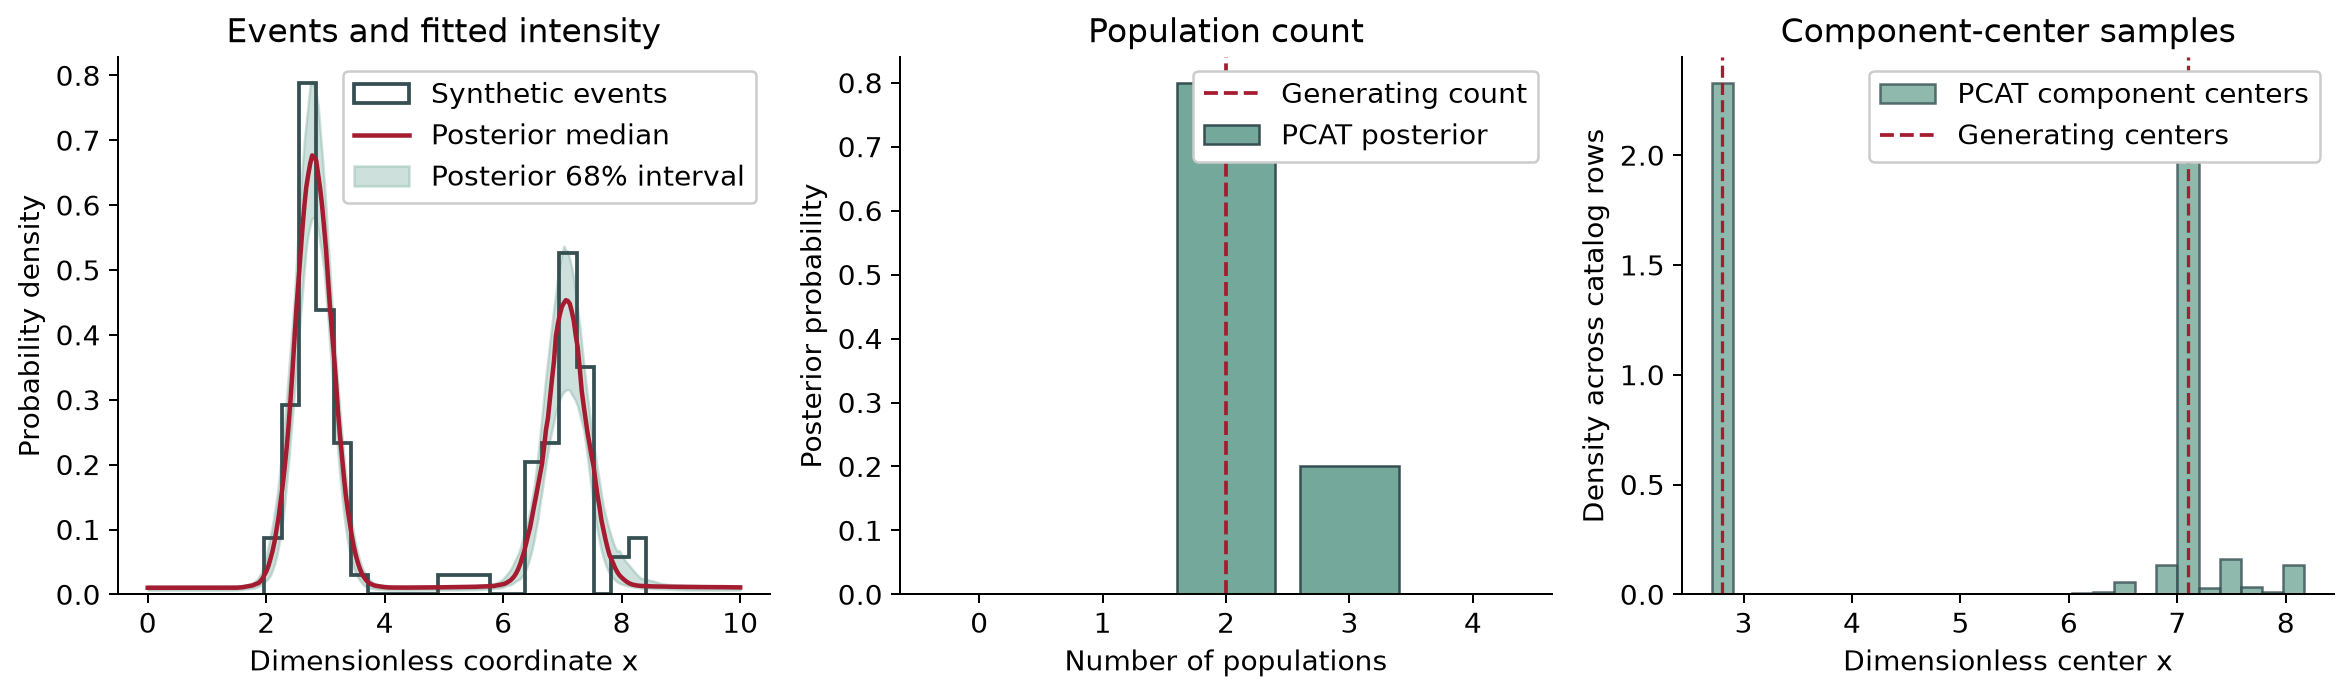

In [12]:
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.rcParams.update({"font.size": 11, "axes.grid": False})
coordinate_grid = np.linspace(LOWER_BOUND, UPPER_BOUND, 300)
posterior_indices = np.linspace(0, len(result["catalog_samples"]) - 1,
                                min(150, len(result["catalog_samples"]))).astype(int)
posterior_densities = []
for index in posterior_indices:
    background = result["base_samples"][index, 0]
    catalog = result["catalog_samples"][index]
    log_density = np.full(coordinate_grid.size, np.log(background))
    total_rate = background * (UPPER_BOUND - LOWER_BOUND)
    for center, width, expected_count in catalog:
        normalization = ndtr((UPPER_BOUND - center) / width) - ndtr((LOWER_BOUND - center) / width)
        standardized = (coordinate_grid - center) / width
        log_density = np.logaddexp(
            log_density,
            np.log(expected_count) - np.log(width) - 0.5 * np.log(2.0 * np.pi)
            - 0.5 * standardized**2 - np.log(normalization),
        )
        total_rate += expected_count
    posterior_densities.append(np.exp(log_density) / total_rate)

lower_density, median_density, upper_density = np.percentile(
    posterior_densities, [16, 50, 84], axis=0,
)
figure, axes = plt.subplots(1, 3, figsize=(13.2, 4.0))
axes[0].hist(events, bins=22, density=True, histtype="step", linewidth=1.5,
             color="#354F52", label="Synthetic events")
axes[0].plot(coordinate_grid, median_density, color="#A51C30", linewidth=1.8,
             label="Posterior median")
axes[0].fill_between(coordinate_grid, lower_density, upper_density,
                     color="#74A89A", alpha=0.35, label="Posterior 68% interval")
axes[0].set(xlabel="Dimensionless coordinate x", ylabel="Probability density",
            title="Events and fitted intensity")
axes[0].legend(loc="upper right", fancybox=True, framealpha=1.0)

axes[1].bar(np.arange(count_probabilities.size), count_probabilities,
            color="#74A89A", edgecolor="#354F52", label="PCAT posterior")
axes[1].axvline(INJECTED_POPULATIONS.shape[0], color="#A51C30", linestyle="--",
                linewidth=1.5, label="Generating count")
axes[1].set(xticks=np.arange(count_probabilities.size), xlabel="Number of populations",
            ylabel="Posterior probability", title="Population count")
axes[1].legend(loc="upper right", fancybox=True, framealpha=1.0)

center_draws = [catalog[:, 0] for catalog in result["catalog_samples"] if len(catalog)]
if center_draws:
    axes[2].hist(np.concatenate(center_draws), bins=28, density=True,
                 color="#74A89A", edgecolor="#354F52", alpha=0.8,
                 label="PCAT component centers")
    for center in INJECTED_POPULATIONS[:, 0]:
        axes[2].axvline(center, color="#A51C30", linestyle="--", linewidth=1.3)
    axes[2].plot([], [], color="#A51C30", linestyle="--", label="Generating centers")
axes[2].set(xlabel="Dimensionless center x", ylabel="Density across catalog rows",
            title="Component-center samples")
axes[2].legend(loc="upper right", fancybox=True, framealpha=1.0)
for axis in axes:
    axis.grid(False)
    axis.spines[["top", "right"]].set_visible(False)
figure.tight_layout()

current_directory = Path.cwd().resolve()
if current_directory.name == "Astrostatistics-Physics-4680-5680":
    course_root = current_directory
else:
    course_root = next(
        parent / "astromusers" / "Astrostatistics-Physics-4680-5680"
        for parent in (current_directory, *current_directory.parents)
        if (parent / "astromusers" / "Astrostatistics-Physics-4680-5680").is_dir()
    )
figure_path = course_root / "examples" / "visuals" / "pcat_transdimensional_assignment.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
print(f"Writing to {figure_path.relative_to(course_root).as_posix()}...")
figure.savefig(figure_path, dpi=300, bbox_inches="tight")
buffer = BytesIO()
figure.savefig(buffer, format="png", dpi=180, bbox_inches="tight")
display(Image(data=buffer.getvalue()))
plt.close(figure)